### Middleware
Middleware provides a way to more tightly control what happens inside the agent. Middleware is useful for the following:

1.Tracking agent behavior with logging, analytics, and debugging.

2.Transforming prompts, tool selection, and output formatting.

3.Adding retries, fallbacks, and early termination logic.

4.Applying rate limits, guardrails, and PII detection.

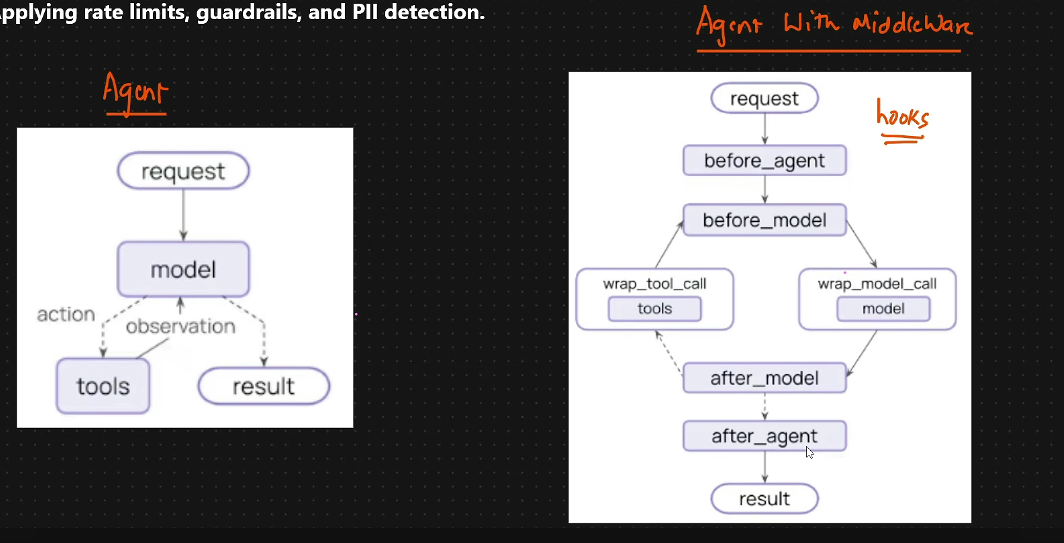

In [19]:
import os
from dotenv import load_dotenv
load_dotenv()
from langchain.agents import create_agent
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain.agents.middleware import SummarizationMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import HumanMessage, SystemMessage
llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",   # or "gemini-2.5-flash"
    api_version="v1beta"
)
agent = create_agent(
    model=llm,
    checkpointer=InMemorySaver(),
    middleware=[
        SummarizationMiddleware(
            model=llm,   # Use Gemini
            trigger=("messages", 10),
            keep=("messages", 4)
        )
    ]
)


In [20]:
### Run with thread id
config={"configurable":{"thread_id":"test-1"}}

In [21]:
# Alternative test data
questions = [
    "What is 2+2?",
    "What is 10*5?",
    "What is 100/4?",
    "What is 15-7?",
    "What is 3*3?",
    "What is 4*4?",
]

for q in questions:
    response=agent.invoke({"messages":[HumanMessage(content=q)]},config)
    print(f"Messages: {response}")
    print(f"Messages: {len(response['messages'])}")

Messages: {'messages': [HumanMessage(content='What is 2+2?', additional_kwargs={}, response_metadata={}, id='b7b21440-ad5e-4221-9003-8d9194467aa3'), AIMessage(content=[{'type': 'text', 'text': '2 + 2 = 4', 'extras': {'signature': 'EmAKXgFpFH0TQc9wfnihTuLACPaee7Ez6OMpluS20eIXylOvr1VevGAHOBhBoStQyA+T67I0kagDt5LypoeM4e3IplZ1wPlrm4dkmvKlS8AfpSxnPXFye7LEizHYKCZ0gwA='}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1d3ab-77b8-7384-9e9c-b99666942c2a-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 8, 'output_tokens': 7, 'total_tokens': 15, 'input_token_details': {'cache_read': 0}})]}
Messages: 2
Messages: {'messages': [HumanMessage(content='What is 2+2?', additional_kwargs={}, response_metadata={}, id='b7b21440-ad5e-4221-9003-8d9194467aa3'), AIMessage(content=[{'type': 'text', 'text': '2 + 2 = 4', 'extras': {'signature': 'EmAKXgFpFH0TQc9

### SUMERRIZATION BASED ON TOKEN SIZE

In [22]:
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage
from langgraph.checkpoint.memory import InMemorySaver

@tool
def search_hotels(city: str) -> str:
    """Search hotels - returns long response to use more tokens."""
    return f"""Hotels in {city}:
    1. Grand Hotel - 5 star, $350/night, spa, pool, gym
    2. City Inn - 4 star, $180/night, business center
    3. Budget Stay - 3 star, $75/night, free wifi"""


agent=create_agent(
    model=llm,
    tools=[search_hotels],
    checkpointer=InMemorySaver(),
    middleware=[
        SummarizationMiddleware(
            model=llm,
            trigger=("tokens",550),
            keep=("tokens",200),
        ),
    ]
)

config = {"configurable": {"thread_id": "test-1"}}

# Token counter (approximate)
def count_tokens(messages):
    total_chars = sum(len(str(m.content)) for m in messages)
    return total_chars // 4  # 4 chars ≈ 1 token


In [23]:
# Run test
cities = ["Paris", "London", "Tokyo", "New York", "Dubai", "Singapore"]

for city in cities:
    response = agent.invoke(
        {"messages": [HumanMessage(content=f"Find hotels in {city}")]},
        config=config
    )
    
    tokens = count_tokens(response["messages"])
    print(f"{city}: ~{tokens} tokens, {len(response['messages'])} messages")
    print(f"{(response['messages'])}")

Paris: ~173 tokens, 4 messages
[HumanMessage(content='Find hotels in Paris', additional_kwargs={}, response_metadata={}, id='4e4d6f02-5edc-4549-91e4-46a66c4f209b'), AIMessage(content=[], additional_kwargs={'function_call': {'name': 'search_hotels', 'arguments': '{"city": "Paris"}'}, '__gemini_function_call_thought_signatures__': {'call_12231032295913720591': 'EmAKXgFpFH0TJ5T3d4JX+OSTBS3lpBBGbXmmQm4RMf9uqUOyUWb9lIPHZ2XVr4Px8quep1n4kG632FLTl2qwD32+DTkrbUum5gvizZBNRr6t4LQixXQ0kFti6P1O5Avu774='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1d3ac-5cc8-7685-842c-ab38eb54a559-0', tool_calls=[{'name': 'search_hotels', 'args': {'city': 'Paris'}, 'id': 'call_12231032295913720591', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 53, 'output_tokens': 16, 'total_tokens': 69, 'input_token_details': {'cache_read': 0}}), ToolMessage(content='Hotels in Paris:\n  

### Summerization based on FRACTION

In [24]:
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage
from langgraph.checkpoint.memory import InMemorySaver
@tool
def search_hotels(city: str) -> str:
    """Search hotels."""
    return f"Hotels in {city}: Grand Hotel $350, City Inn $180, Budget Stay $75"
# LOW fraction for testing!
agent = create_agent(
    model=llm,
    tools=[search_hotels],
    checkpointer=InMemorySaver(),
    middleware=[
        SummarizationMiddleware(
            model=llm,
            trigger=("fraction", 0.005),  # 0.5% = ~640 tokens
            keep=("fraction", 0.002),     # 0.2% = ~256 tokens
        ),
    ],
)
config = {"configurable": {"thread_id": "test-1"}}
# Token counter
def count_tokens(messages):
    return sum(len(str(m.content)) for m in messages) // 4
# Test
cities = ["Paris", "London", "Tokyo", "New York", "Dubai", "Singapore"]
for city in cities:
    response = agent.invoke(
        {"messages": [HumanMessage(content=f"Hotels in {city}")]},
        config=config
    )
    tokens = count_tokens(response["messages"])
    fraction = tokens / 128000  # context fraction
    print(f"{city}: ~{tokens} tokens ({fraction:.4%}), {len(response['messages'])} msgs")
    print(response['messages'])


Paris: ~103 tokens (0.0805%), 4 msgs
[HumanMessage(content='Hotels in Paris', additional_kwargs={}, response_metadata={}, id='0d795647-1ec2-4c7b-a7a6-ea27fc17398d'), AIMessage(content=[], additional_kwargs={'function_call': {'name': 'search_hotels', 'arguments': '{"city": "Paris"}'}, '__gemini_function_call_thought_signatures__': {'call_16007990270752408514': 'EmAKXgFpFH0TqqiGxEZe4Qkq0ygYeGu0p9kjmv0TEncv6Vi+ogMY/iy35/Q7NO/E+RNxmaNjmCzsOqy8v1gsNqKhcTa6FsL6LOsa4/Rtnmsd7wt/qN8uhRj59/J2I65mAiU='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1d3ae-4071-73f8-a779-ce9a8e687ef2-0', tool_calls=[{'name': 'search_hotels', 'args': {'city': 'Paris'}, 'id': 'call_16007990270752408514', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 45, 'output_tokens': 16, 'total_tokens': 61, 'input_token_details': {'cache_read': 0}}), ToolMessage(content='Hotels in Paris: Gr

### Human In the Loop MiddleWare
Pause agent execution for human approval, editing, or rejection of tool calls before they execute. Human-in-the-loop is useful for the following:

1.High-stakes operations requiring human approval (e.g. database writes, financial transactions).

2.Compliance workflows where human oversight is mandatory.

3.Long-running conversations where human feedback guides the agent.

In [25]:
from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver

def read_email_tool(email_id: str) -> str:
    """Mock function to read an email by its ID."""
    return f"Email content for ID: {email_id}"

def send_email_tool(recipient: str, subject: str, body: str) -> str:
    """Mock function to send an email."""
    return f"Email sent to {recipient} with subject '{subject}'"

In [26]:
agent=create_agent(
    model=llm,
    tools=[read_email_tool,send_email_tool],
    checkpointer=InMemorySaver(),
    middleware=[
        HumanInTheLoopMiddleware(
            interrupt_on={
                "send_email_tool":{
                    "allowed_decisions":["approve","edit","reject"]
                },
                "read_email_tool":False,

            }
        )
    ]
)


In [27]:
config = {"configurable": {"thread_id": "test-approve"}}
# Step 1: Request
result = agent.invoke(
    {"messages": [HumanMessage(content="Send email to john@test.com with subject 'Hello' and body 'How are you?'")]},
    config=config
)

In [28]:
result

{'messages': [HumanMessage(content="Send email to john@test.com with subject 'Hello' and body 'How are you?'", additional_kwargs={}, response_metadata={}, id='1d748886-2b6b-47fe-b963-e4880381d159'),
  AIMessage(content=[], additional_kwargs={'function_call': {'name': 'send_email_tool', 'arguments': '{"recipient": "john@test.com", "body": "How are you?", "subject": "Hello"}'}, '__gemini_function_call_thought_signatures__': {'call_12399217546642876334': 'EmAKXgFpFH0TQEQn88b60QP0U4mPNZc6RMDM43T+qHp7RgcVqlhHaydNOnWRdig39A4zl0mk5o93h1g6Lycro3rGg1KjnvtzFyoWLkw8ssYH/ysReMkNicP6UnwE7psAbOQ='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1d3af-3d3c-72de-9ef6-423903e14722-0', tool_calls=[{'name': 'send_email_tool', 'args': {'recipient': 'john@test.com', 'body': 'How are you?', 'subject': 'Hello'}, 'id': 'call_12399217546642876334', 'type': 'tool_call'}], invalid_tool_calls=[], usage_me

In [29]:
from langgraph.types import Command
# Step 2: Approve
if "__interrupt__" in result:
    print("⏸️ Paused! Approving...")
    
    result = agent.invoke(
        Command(
            resume={
                "decisions": [
                    {"type": "approve"}
                ]
            }
        ),
        config=config
    )
    
    print(f"✅ Result: {result['messages'][-1].content}")


⏸️ Paused! Approving...
✅ Result: [{'type': 'text', 'text': 'Email sent successfully to john@test.com.', 'extras': {'signature': 'EmAKXgFpFH0TdppEs/SLvNFT4hJck447EuB2l+rAAtitNls1RMnkWA46KCp3w/z4C9Ur5jprc19uzfQW2D3GoRvde+3QI8+MTKXO87ME1iIojsEMKcz/qkad5Sh5J3Hv/Kg='}}]


In [30]:
result

{'messages': [HumanMessage(content="Send email to john@test.com with subject 'Hello' and body 'How are you?'", additional_kwargs={}, response_metadata={}, id='1d748886-2b6b-47fe-b963-e4880381d159'),
  AIMessage(content=[], additional_kwargs={'function_call': {'name': 'send_email_tool', 'arguments': '{"recipient": "john@test.com", "body": "How are you?", "subject": "Hello"}'}, '__gemini_function_call_thought_signatures__': {'call_12399217546642876334': 'EmAKXgFpFH0TQEQn88b60QP0U4mPNZc6RMDM43T+qHp7RgcVqlhHaydNOnWRdig39A4zl0mk5o93h1g6Lycro3rGg1KjnvtzFyoWLkw8ssYH/ysReMkNicP6UnwE7psAbOQ='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1d3af-3d3c-72de-9ef6-423903e14722-0', tool_calls=[{'name': 'send_email_tool', 'args': {'recipient': 'john@test.com', 'body': 'How are you?', 'subject': 'Hello'}, 'id': 'call_12399217546642876334', 'type': 'tool_call'}], invalid_tool_calls=[], usage_me

REJECT

In [31]:
from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver


def read_email_tool(email_id: str) -> str:
    """Mock function to read an email by its ID."""
    return f"Email content for ID: {email_id}"

def send_email_tool(recipient: str, subject: str, body: str) -> str:
    """Mock function to send an email."""
    return f"Email sent to {recipient} with subject '{subject}'"

agent = create_agent(
    model=llm,
    tools=[read_email_tool,send_email_tool],
    checkpointer=InMemorySaver(),
    middleware=[
        HumanInTheLoopMiddleware(
            interrupt_on={
                "send_email_tool": {
                    "allowed_decisions": ["approve", "edit", "reject"],
                },
                "read_email_tool": False,
            }
        ),
    ],
)


In [32]:
config = {"configurable": {"thread_id": "test-reject"}}
# Step 1: Request
result = agent.invoke(
    {"messages": [HumanMessage(content="Send email to john@test.com with subject 'Hello' and body 'How are you?'")]},
    config=config)

In [33]:
# Step 2: Reject
if "__interrupt__" in result:
    print("⏸️ Paused! Approving...")
    
    result = agent.invoke(
        Command(
            resume={
                "decisions": [
                    {"type": "reject"}
                ]
            }
        ),
        config=config
    )
    
    print(f"✅ Result: {result['messages'][-1].content}")

⏸️ Paused! Approving...
✅ Result: [{'type': 'text', 'text': 'The email could not be sent because the tool call was rejected by the user. Let me know if you would like to try again or need help with something else.', 'extras': {'signature': 'EmAKXgFpFH0TPNfYarvDH2TEjsaksUr1EUCoH7ICRnNnfmYN2mQXJbXO2Rf2l3q65zzfpPyL4Y3NLyiPuZzhyl/dIDRawesLDV8a5iWp8S0BMtyyC/OLJri4yV7/9V1rP8Q='}}]


In [34]:
result

{'messages': [HumanMessage(content="Send email to john@test.com with subject 'Hello' and body 'How are you?'", additional_kwargs={}, response_metadata={}, id='2b16c0cc-b83e-4337-91c3-8e10834fc588'),
  AIMessage(content=[], additional_kwargs={'function_call': {'name': 'send_email_tool', 'arguments': '{"recipient": "john@test.com", "subject": "Hello", "body": "How are you?"}'}, '__gemini_function_call_thought_signatures__': {'call_7391343765752965014': 'EmAKXgFpFH0T87nUFIAgJ1DRw3pE/65xTQbIq5HVX0wNPForfbT0IWGAjE1Nswa2TJE0sFGvzqSYEOO9krA8R6lfN7GXmEOh6iWushglfDgIV0078/vVSYlheoVIhnlSvHU='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1d3af-5f0e-722a-8033-fe2fb006c919-0', tool_calls=[{'name': 'send_email_tool', 'args': {'recipient': 'john@test.com', 'subject': 'Hello', 'body': 'How are you?'}, 'id': 'call_7391343765752965014', 'type': 'tool_call'}], invalid_tool_calls=[], usage_meta

Editing

In [35]:
from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver


def read_email_tool(email_id: str) -> str:
    """Mock function to read an email by its ID."""
    return f"Email content for ID: {email_id}"

def send_email_tool(recipient: str, subject: str, body: str) -> str:
    """Mock function to send an email."""
    return f"Email sent to {recipient} with subject '{subject}'"

agent = create_agent(
    model=llm,
    tools=[read_email_tool,send_email_tool],
    checkpointer=InMemorySaver(),
    middleware=[
        HumanInTheLoopMiddleware(
            interrupt_on={
                "send_email_tool": {
                    "allowed_decisions": ["approve", "edit", "reject"],
                },
                "read_email_tool": False,
            }
        ),
    ],
)


In [36]:
config = {"configurable": {"thread_id": "test-edit"}}

# Step 1: Request (with wrong info)
result = agent.invoke(
    {"messages": [HumanMessage(content="Send email to wrong@email.com with subject 'Test' and body 'Hello'")]},
    config=config
)

In [37]:
result

{'messages': [HumanMessage(content="Send email to wrong@email.com with subject 'Test' and body 'Hello'", additional_kwargs={}, response_metadata={}, id='c8e4d141-1165-49d3-a8cf-43604ac05018'),
  AIMessage(content=[], additional_kwargs={'function_call': {'name': 'send_email_tool', 'arguments': '{"recipient": "wrong@email.com", "subject": "Test", "body": "Hello"}'}, '__gemini_function_call_thought_signatures__': {'call_15651070630882598055': 'EmAKXgFpFH0TF8KzQWoWhr502TN2S9PP/4DDXykfstToY5TC6dYI1CkJmP3r+6ZioVMpvoZATKvihkumwX5y2HXFuiHNASyah6PUXYvZs2pUEZQQeaox3brb7mJxzonA8vk='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1d3af-6834-770e-af98-152b238e4296-0', tool_calls=[{'name': 'send_email_tool', 'args': {'recipient': 'wrong@email.com', 'subject': 'Test', 'body': 'Hello'}, 'id': 'call_15651070630882598055', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tok

In [38]:
# Step 2: Edit and approve
if "__interrupt__" in result:
    print("⏸️ Paused! Editing...")
    
    result = agent.invoke(
        Command(
            resume={
                "decisions": [
                    {
                        "type": "edit",
                        "edited_action": {
                            "name": "send_email_tool",      # Tool name
                            "args": {                   # New arguments
                                "recipient": "correct@email.com",
                                "subject": "Corrected Subject",
                                "body": "This was edited by human before sending"
                            }
                        }
                    }
                ]
            }
        ),
        config=config
    )
    
    print(f"✏️ Result: {result['messages'][-1].content}")

⏸️ Paused! Editing...
✏️ Result: [{'type': 'text', 'text': 'The email has been sent successfully. Please note that the recipient, subject, and body were modified by a human reviewer before the email was actually sent (it was sent to `correct@email.com` with the subject `Corrected Subject`).', 'extras': {'signature': 'EmAKXgFpFH0TvrWMpzFHi9iAAYCggHM0OeVpEFMWX71bgs4zDsyGsnlJwD24BBpVYu3ZmY/eQVC6h+7GEhYWO5KT0jNb/V8eInNFaHnDeoin1Q1+coJR4qyAMisE01+ClgQ='}}]


In [39]:
result

{'messages': [HumanMessage(content="Send email to wrong@email.com with subject 'Test' and body 'Hello'", additional_kwargs={}, response_metadata={}, id='c8e4d141-1165-49d3-a8cf-43604ac05018'),
  AIMessage(content=[], additional_kwargs={'function_call': {'name': 'send_email_tool', 'arguments': '{"recipient": "wrong@email.com", "subject": "Test", "body": "Hello"}'}, '__gemini_function_call_thought_signatures__': {'call_15651070630882598055': 'EmAKXgFpFH0TF8KzQWoWhr502TN2S9PP/4DDXykfstToY5TC6dYI1CkJmP3r+6ZioVMpvoZATKvihkumwX5y2HXFuiHNASyah6PUXYvZs2pUEZQQeaox3brb7mJxzonA8vk='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1d3af-6834-770e-af98-152b238e4296-0', tool_calls=[{'name': 'send_email_tool', 'args': {'recipient': 'wrong@email.com', 'subject': 'Test', 'body': 'Hello'}, 'id': 'call_15651070630882598055', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tok